# Dataset Audit – Skin Diseases Image Dataset

This notebook evaluates dataset structure, class distribution, image properties, file integrity, and possible duplicate images before preprocessing or model development. A rigorous audit helps identify class imbalance, inconsistent acquisition characteristics, unreadable files, and duplicate-related leakage that could bias evaluation or produce misleadingly high classification performance.

The raw dataset is treated as read-only. Generated tables and figures are written only to `reports/`.

## 1. Imports and Configuration

The project root is detected by searching upward for the expected dataset directory, so the notebook works when launched from either the repository root or `notebooks/`.

In [1]:
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path
import hashlib
import re
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from PIL import Image, ImageOps
from tqdm.auto import tqdm

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")

DATA_RELATIVE_PATH = Path("data/raw/skin-diseases-image-dataset/IMG_CLASSES")


def find_project_root(start: Path) -> Path:
    """Find the nearest parent containing the expected dataset directory."""
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / DATA_RELATIVE_PATH).is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root. Expected to find "
        f"'{DATA_RELATIVE_PATH.as_posix()}' in the current directory or one of its parents."
    )


PROJECT_ROOT = find_project_root(Path.cwd())
DATA_DIR = PROJECT_ROOT / DATA_RELATIVE_PATH
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Dataset directory does not exist: {DATA_DIR}")

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset directory: {DATA_DIR}")
print(f"Reports directory: {REPORTS_DIR}")

Project root: C:\Projekt konferencyjny Turcja\skin-disease-classification
Dataset directory: C:\Projekt konferencyjny Turcja\skin-disease-classification\data\raw\skin-diseases-image-dataset\IMG_CLASSES
Reports directory: C:\Projekt konferencyjny Turcja\skin-disease-classification\reports


## 2. Dataset Structure

Class directories and files are discovered directly from the filesystem. Numeric text embedded in directory names is never used as a source of class counts.

In [2]:
EXPECTED_CLASS_COUNT = 10
JPG_EXTENSIONS = {".jpg", ".jpeg"}


def clean_class_label(directory_name: str) -> str:
    """Remove ordering and count-like affixes from a class directory name."""
    label = re.sub(r"^\s*\d+\.\s*", "", directory_name)
    label = re.sub(r"\s*(?:-\s*)?\d+(?:\.\d+)?[kK]?\s*$", "", label)
    return label.strip(" -")


class_dirs = sorted(
    (path for path in DATA_DIR.iterdir() if path.is_dir()),
    key=lambda path: path.name.casefold(),
)
class_records = [
    {
        "original_directory_name": path.name,
        "class_name": clean_class_label(path.name),
        "directory": path,
    }
    for path in class_dirs
]
class_name_by_directory = {
    record["original_directory_name"]: record["class_name"]
    for record in class_records
}

all_files = sorted(
    (path for directory in class_dirs for path in directory.rglob("*") if path.is_file()),
    key=lambda path: path.as_posix().casefold(),
)
jpg_files = [path for path in all_files if path.suffix.lower() in JPG_EXTENSIONS]

print(f"Number of class directories: {len(class_dirs):,}")
print("Original class directory names:")
for directory in class_dirs:
    print(f"  - {directory.name}")
print(f"Total number of files in class directories: {len(all_files):,}")
print(f"Total number of JPG/JPEG files: {len(jpg_files):,}")
print(
    f"Exactly {EXPECTED_CLASS_COUNT} class directories present: "
    f"{'PASS' if len(class_dirs) == EXPECTED_CLASS_COUNT else 'FAIL'}"
)

if len(class_dirs) != EXPECTED_CLASS_COUNT:
    raise RuntimeError(
        f"Expected {EXPECTED_CLASS_COUNT} class directories, but found {len(class_dirs)}. "
        "Review the dataset layout before continuing."
    )
if not all_files:
    raise RuntimeError("No files were found inside the class directories.")
if len(set(class_name_by_directory.values())) != len(class_name_by_directory):
    raise RuntimeError("Automatic label cleaning produced duplicate class names.")

Number of class directories: 10
Original class directory names:
  - 1. Eczema 1677
  - 10. Warts Molluscum and other Viral Infections - 2103
  - 2. Melanoma 15.75k
  - 3. Atopic Dermatitis - 1.25k
  - 4. Basal Cell Carcinoma (BCC) 3323
  - 5. Melanocytic Nevi (NV) - 7970
  - 6. Benign Keratosis-like Lesions (BKL) 2624
  - 7. Psoriasis pictures Lichen Planus and related diseases - 2k
  - 8. Seborrheic Keratoses and other Benign Tumors - 1.8k
  - 9. Tinea Ringworm Candidiasis and other Fungal Infections - 1.7k
Total number of files in class directories: 27,153
Total number of JPG/JPEG files: 27,153
Exactly 10 class directories present: PASS


## 3. Class Distribution

The maximum-to-minimum ratio summarizes class-size inequality without trusting counts written in folder names.

,class_name,image_count,percentage
0,Atopic Dermatitis,"1,257",4.63%
1,Eczema,"1,677",6.18%
2,Tinea Ringworm Candidiasis and other Fungal Infections,"1,702",6.27%
3,Seborrheic Keratoses and other Benign Tumors,"1,847",6.80%
4,Psoriasis pictures Lichen Planus and related diseases,"2,055",7.57%
5,Benign Keratosis-like Lesions (BKL),"2,079",7.66%
6,Warts Molluscum and other Viral Infections,"2,103",7.75%
7,Melanoma,"3,140",11.56%
8,Basal Cell Carcinoma (BCC),"3,323",12.24%
9,Melanocytic Nevi (NV),"7,970",29.35%


Total images: 27,153
Largest class: Melanocytic Nevi (NV) (7,970 images)
Smallest class: Atopic Dermatitis (1,257 images)
Maximum-to-minimum class size ratio: 6.34:1
Class imbalance is present because the observed class sizes are unequal. Its effect should be addressed and measured during later model development.


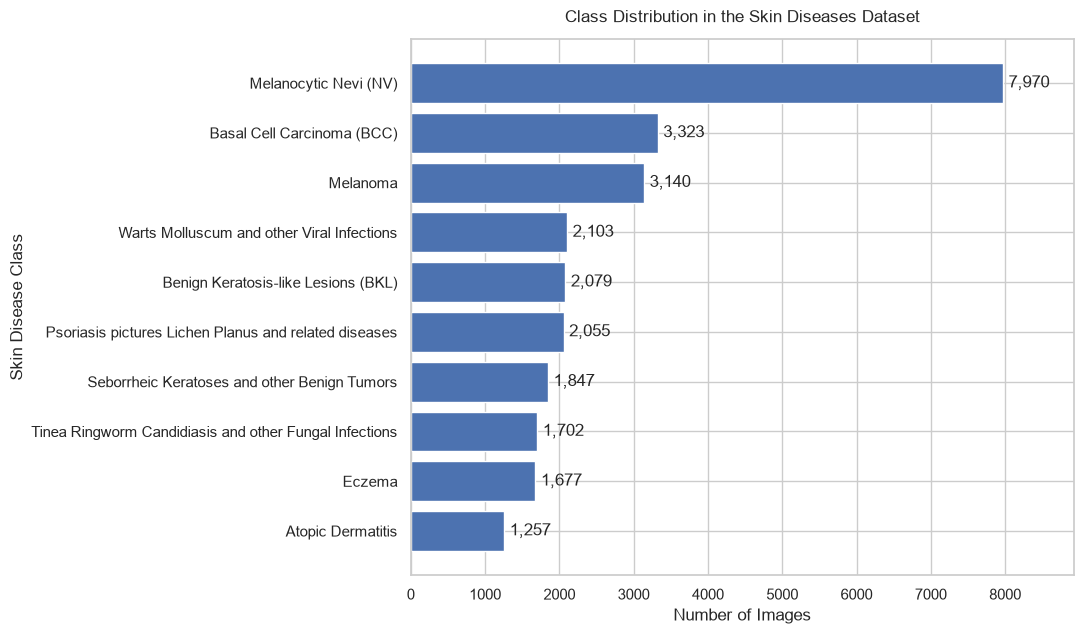

In [3]:
file_counts_by_directory = Counter(
    path.relative_to(DATA_DIR).parts[0] for path in all_files
)
class_distribution = pd.DataFrame(
    {
        "class_name": [record["class_name"] for record in class_records],
        "image_count": [
            file_counts_by_directory[record["original_directory_name"]]
            for record in class_records
        ],
    }
)
class_distribution["percentage"] = (
    100 * class_distribution["image_count"] / class_distribution["image_count"].sum()
)
class_distribution = class_distribution.sort_values(
    "image_count", ascending=True, ignore_index=True
)
class_distribution.to_csv(
    REPORTS_DIR / "01_class_distribution.csv", index=False, encoding="utf-8"
)

display(
    class_distribution.style.format(
        {"image_count": "{:,}", "percentage": "{:.2f}%"}
    )
)

total_images = int(class_distribution["image_count"].sum())
largest_class_row = class_distribution.loc[class_distribution["image_count"].idxmax()]
smallest_class_row = class_distribution.loc[class_distribution["image_count"].idxmin()]
imbalance_ratio = largest_class_row["image_count"] / smallest_class_row["image_count"]

print(f"Total images: {total_images:,}")
print(
    f"Largest class: {largest_class_row['class_name']} "
    f"({int(largest_class_row['image_count']):,} images)"
)
print(
    f"Smallest class: {smallest_class_row['class_name']} "
    f"({int(smallest_class_row['image_count']):,} images)"
)
print(f"Maximum-to-minimum class size ratio: {imbalance_ratio:.2f}:1")
if np.isclose(imbalance_ratio, 1.0):
    print("The observed class counts are balanced.")
else:
    print(
        "Class imbalance is present because the observed class sizes are unequal. "
        "Its effect should be addressed and measured during later model development."
    )

fig, ax = plt.subplots(figsize=(11, 6.5))
bars = ax.barh(
    class_distribution["class_name"],
    class_distribution["image_count"],
    color=sns.color_palette("deep")[0],
)
ax.bar_label(
    bars,
    labels=[f"{value:,}" for value in class_distribution["image_count"]],
    padding=4,
)
ax.set_title("Class Distribution in the Skin Diseases Dataset", pad=12)
ax.set_xlabel("Number of Images")
ax.set_ylabel("Skin Disease Class")
ax.margins(x=0.12)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Image Format Validation

Extensions are normalized to lowercase. Extension consistency does not prove that files are decodable, so content integrity is checked separately.

In [4]:
extension_counts = pd.Series(
    Counter(path.suffix.lower() or "[no extension]" for path in all_files),
    name="number_of_files",
).sort_values(ascending=False)
extension_table = extension_counts.rename_axis("extension").reset_index()
extension_table["percentage"] = 100 * extension_table["number_of_files"] / len(all_files)

display(
    extension_table.style.format(
        {"number_of_files": "{:,}", "percentage": "{:.2f}%"}
    )
)
format_is_consistent = set(extension_table["extension"]).issubset(JPG_EXTENSIONS)
print(
    "All discovered files use JPG/JPEG extensions: "
    f"{'PASS' if format_is_consistent else 'FAIL'}"
)

,extension,number_of_files,percentage
0,.jpg,"27,153",100.00%


All discovered files use JPG/JPEG extensions: PASS


## 5. Image Integrity Check

Every discovered file is opened and verified with Pillow. Invalid files are reported but never deleted, moved, renamed, or modified. Metadata is collected in the same scan to avoid unnecessary repeated work.

In [5]:
integrity_records = []
metadata_records = []

for path in tqdm(all_files, desc="Verifying images", unit="image"):
    relative_path = path.relative_to(PROJECT_ROOT).as_posix()
    directory_name = path.relative_to(DATA_DIR).parts[0]
    class_name = class_name_by_directory[directory_name]
    try:
        with Image.open(path) as image:
            image.verify()
        with Image.open(path) as image:
            width, height = image.size
            image_mode = image.mode
        if width <= 0 or height <= 0:
            raise ValueError(f"Invalid image dimensions: {width} x {height}")

        integrity_records.append(
            {
                "file_path": relative_path,
                "class_name": class_name,
                "is_valid": True,
                "error_message": None,
            }
        )
        metadata_records.append(
            {
                "file_path": relative_path,
                "file_name": path.name,
                "class_name": class_name,
                "width": width,
                "height": height,
                "aspect_ratio": width / height,
                "image_mode": image_mode,
                "file_size_kb": path.stat().st_size / 1024,
            }
        )
    except Exception as error:
        integrity_records.append(
            {
                "file_path": relative_path,
                "class_name": class_name,
                "is_valid": False,
                "error_message": f"{type(error).__name__}: {error}",
            }
        )

df_integrity = pd.DataFrame(integrity_records)
df_corrupted = df_integrity.loc[~df_integrity["is_valid"]].reset_index(drop=True)
df_images = pd.DataFrame(metadata_records)

print(f"Total checked images: {len(df_integrity):,}")
print(f"Valid images: {int(df_integrity['is_valid'].sum()):,}")
print(f"Corrupted or unreadable images: {len(df_corrupted):,}")
if df_corrupted.empty:
    print("No corrupted or unreadable images were detected.")
else:
    display(df_corrupted)
if df_images.empty:
    raise RuntimeError("No valid images remain for metadata analysis.")

Verifying images:   0%|          | 0/27153 [00:00<?, ?image/s]

Total checked images: 27,153
Valid images: 27,153
Corrupted or unreadable images: 0
No corrupted or unreadable images were detected.


## 6. Image Metadata Analysis

Resolution, aspect ratio, color mode, and file size guide later preprocessing decisions. All stored paths are project-relative.

,file_path,file_name,class_name,width,height,aspect_ratio,image_mode,file_size_kb
0,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/0_0.jpg,0_0.jpg,Eczema,294,222,1.32,RGB,17.46
1,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/0_1.jpg,0_1.jpg,Eczema,294,222,1.32,RGB,21.05
2,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/0_10.jpg,0_10.jpg,Eczema,294,222,1.32,RGB,18.66
3,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/0_11.jpg,0_11.jpg,Eczema,294,222,1.32,RGB,21.20
4,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/0_12.jpg,0_12.jpg,Eczema,294,222,1.32,RGB,22.69


,count,mean,std,min,25%,50%,75%,max
width,"27,153.00",678.83,211.51,294.00,512.00,600.00,720.00,"1,024.00"
height,"27,153.00",569.92,220.94,222.00,450.00,479.00,685.00,"1,128.00"
aspect_ratio,"27,153.00",1.24,0.25,0.62,1.00,1.33,1.48,1.63
file_size_kb,"27,153.00",200.68,157.36,7.39,77.98,136.45,278.25,927.43


Minimum image resolution by pixel count: 294 × 222
Maximum image resolution by pixel count: 1024 × 1024
Median width: 600.0 pixels
Median height: 479.0 pixels
Number of unique resolutions: 390
Most common resolutions:


,width,height,image_count
0,600,450,7461
1,1024,1024,3947
2,512,512,3140
3,720,472,2340
4,294,222,2031
5,720,480,1061
6,1024,680,659
7,1024,768,598
8,480,720,535
9,477,720,333


Image modes:


,image_mode,image_count
0,RGB,27153


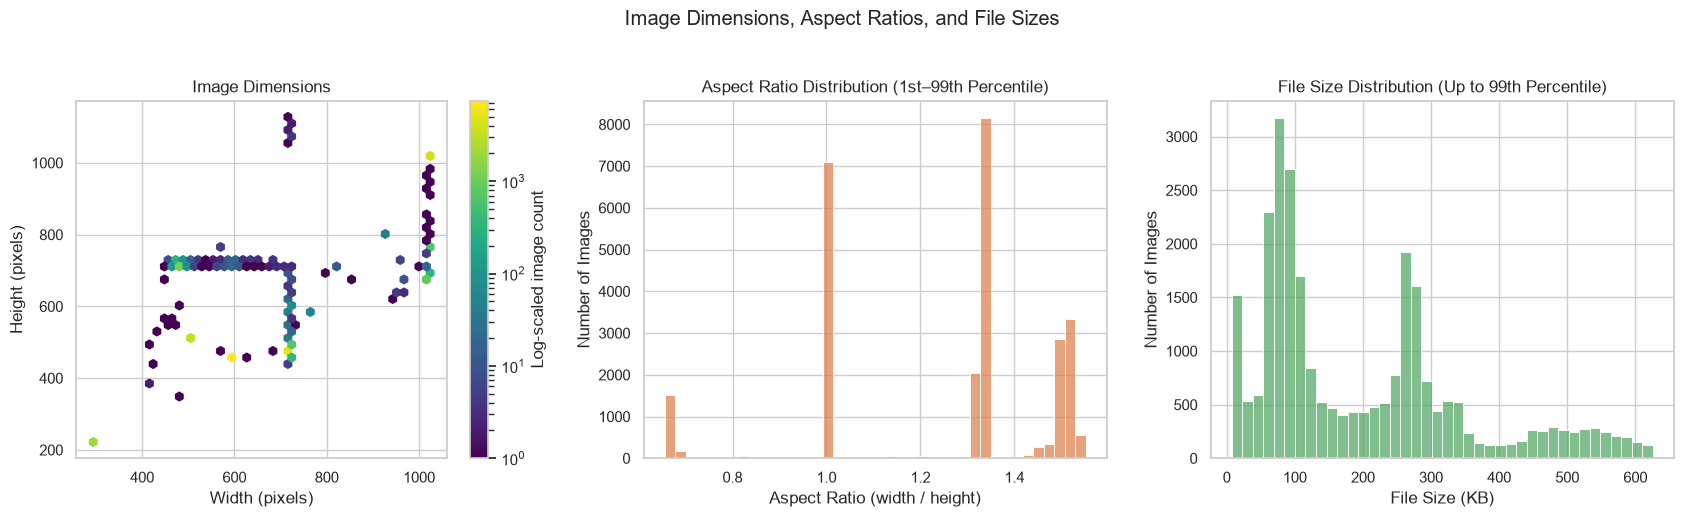

In [6]:
df_images.to_csv(REPORTS_DIR / "01_image_metadata.csv", index=False, encoding="utf-8")
display(df_images.head())

metadata_statistics = df_images[
    ["width", "height", "aspect_ratio", "file_size_kb"]
].describe().T
display(metadata_statistics)

resolution_view = df_images.assign(pixel_count=df_images["width"] * df_images["height"])
minimum_resolution_row = resolution_view.loc[resolution_view["pixel_count"].idxmin()]
maximum_resolution_row = resolution_view.loc[resolution_view["pixel_count"].idxmax()]
resolution_counts = (
    df_images.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .rename("image_count")
    .reset_index()
)
image_mode_counts = (
    df_images["image_mode"]
    .value_counts()
    .rename_axis("image_mode")
    .reset_index(name="image_count")
)

print(
    "Minimum image resolution by pixel count: "
    f"{int(minimum_resolution_row['width'])} × {int(minimum_resolution_row['height'])}"
)
print(
    "Maximum image resolution by pixel count: "
    f"{int(maximum_resolution_row['width'])} × {int(maximum_resolution_row['height'])}"
)
print(f"Median width: {df_images['width'].median():,.1f} pixels")
print(f"Median height: {df_images['height'].median():,.1f} pixels")
print(f"Number of unique resolutions: {len(resolution_counts):,}")
print("Most common resolutions:")
display(resolution_counts.head(10))
print("Image modes:")
display(image_mode_counts)

aspect_lower, aspect_upper = df_images["aspect_ratio"].quantile([0.01, 0.99])
size_upper = df_images["file_size_kb"].quantile(0.99)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

dimension_plot = axes[0].hexbin(
    df_images["width"],
    df_images["height"],
    gridsize=45,
    bins="log",
    mincnt=1,
    cmap="viridis",
)
axes[0].set_title("Image Dimensions")
axes[0].set_xlabel("Width (pixels)")
axes[0].set_ylabel("Height (pixels)")
fig.colorbar(dimension_plot, ax=axes[0], label="Log-scaled image count")

sns.histplot(
    data=df_images.loc[df_images["aspect_ratio"].between(aspect_lower, aspect_upper)],
    x="aspect_ratio",
    bins=40,
    ax=axes[1],
    color=sns.color_palette("deep")[1],
)
axes[1].set_title("Aspect Ratio Distribution (1st–99th Percentile)")
axes[1].set_xlabel("Aspect Ratio (width / height)")
axes[1].set_ylabel("Number of Images")

sns.histplot(
    data=df_images.loc[df_images["file_size_kb"] <= size_upper],
    x="file_size_kb",
    bins=40,
    ax=axes[2],
    color=sns.color_palette("deep")[2],
)
axes[2].set_title("File Size Distribution (Up to 99th Percentile)")
axes[2].set_xlabel("File Size (KB)")
axes[2].set_ylabel("Number of Images")

fig.suptitle("Image Dimensions, Aspect Ratios, and File Sizes", y=1.03)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_image_properties.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Class-Level Image Size Analysis

Class-specific medians can reveal visible differences in image acquisition or source characteristics. The table is descriptive only and does not establish why differences exist.

In [7]:
class_size_summary = (
    df_images.groupby("class_name")
    .agg(
        image_count=("file_path", "size"),
        median_width=("width", "median"),
        median_height=("height", "median"),
        median_aspect_ratio=("aspect_ratio", "median"),
    )
    .sort_values("image_count", ascending=False)
)
display(
    class_size_summary.style.format(
        {
            "image_count": "{:,}",
            "median_width": "{:.1f}",
            "median_height": "{:.1f}",
            "median_aspect_ratio": "{:.3f}",
        }
    )
)

width_median_range = (
    class_size_summary["median_width"].min(),
    class_size_summary["median_width"].max(),
)
height_median_range = (
    class_size_summary["median_height"].min(),
    class_size_summary["median_height"].max(),
)
print(
    "Across classes, median width ranges from "
    f"{width_median_range[0]:,.1f} to {width_median_range[1]:,.1f} pixels, "
    "and median height ranges from "
    f"{height_median_range[0]:,.1f} to {height_median_range[1]:,.1f} pixels."
)
print(
    "These observed differences should be considered when defining a common image size; "
    "their source cannot be determined from dimensions alone."
)

,image_count,median_width,median_height,median_aspect_ratio
class_name,,,,
Melanocytic Nevi (NV),"7,970",600.0,450.0,1.333
Basal Cell Carcinoma (BCC),"3,323",1024.0,1024.0,1.000
Melanoma,"3,140",512.0,512.0,1.000
Warts Molluscum and other Viral Infections,"2,103",720.0,472.0,1.446
Benign Keratosis-like Lesions (BKL),"2,079",1024.0,1024.0,1.000
Psoriasis pictures Lichen Planus and related diseases,"2,055",720.0,479.0,1.488
Seborrheic Keratoses and other Benign Tumors,"1,847",720.0,475.0,1.500
Tinea Ringworm Candidiasis and other Fungal Infections,"1,702",720.0,477.0,1.500
Eczema,"1,677",720.0,477.0,1.500


Across classes, median width ranges from 294.0 to 1,024.0 pixels, and median height ranges from 222.0 to 1,024.0 pixels.
These observed differences should be considered when defining a common image size; their source cannot be determined from dimensions alone.


## 8. Reproducible Random Image Samples

Three images per class are sampled with seed 42 for visual inspection of quality, framing, backgrounds, and artifacts such as text, rulers, markings, or borders. Such artifacts may become unintended shortcuts for a neural network. This is a data-quality check only and is not used to make medical diagnoses or clinical claims.

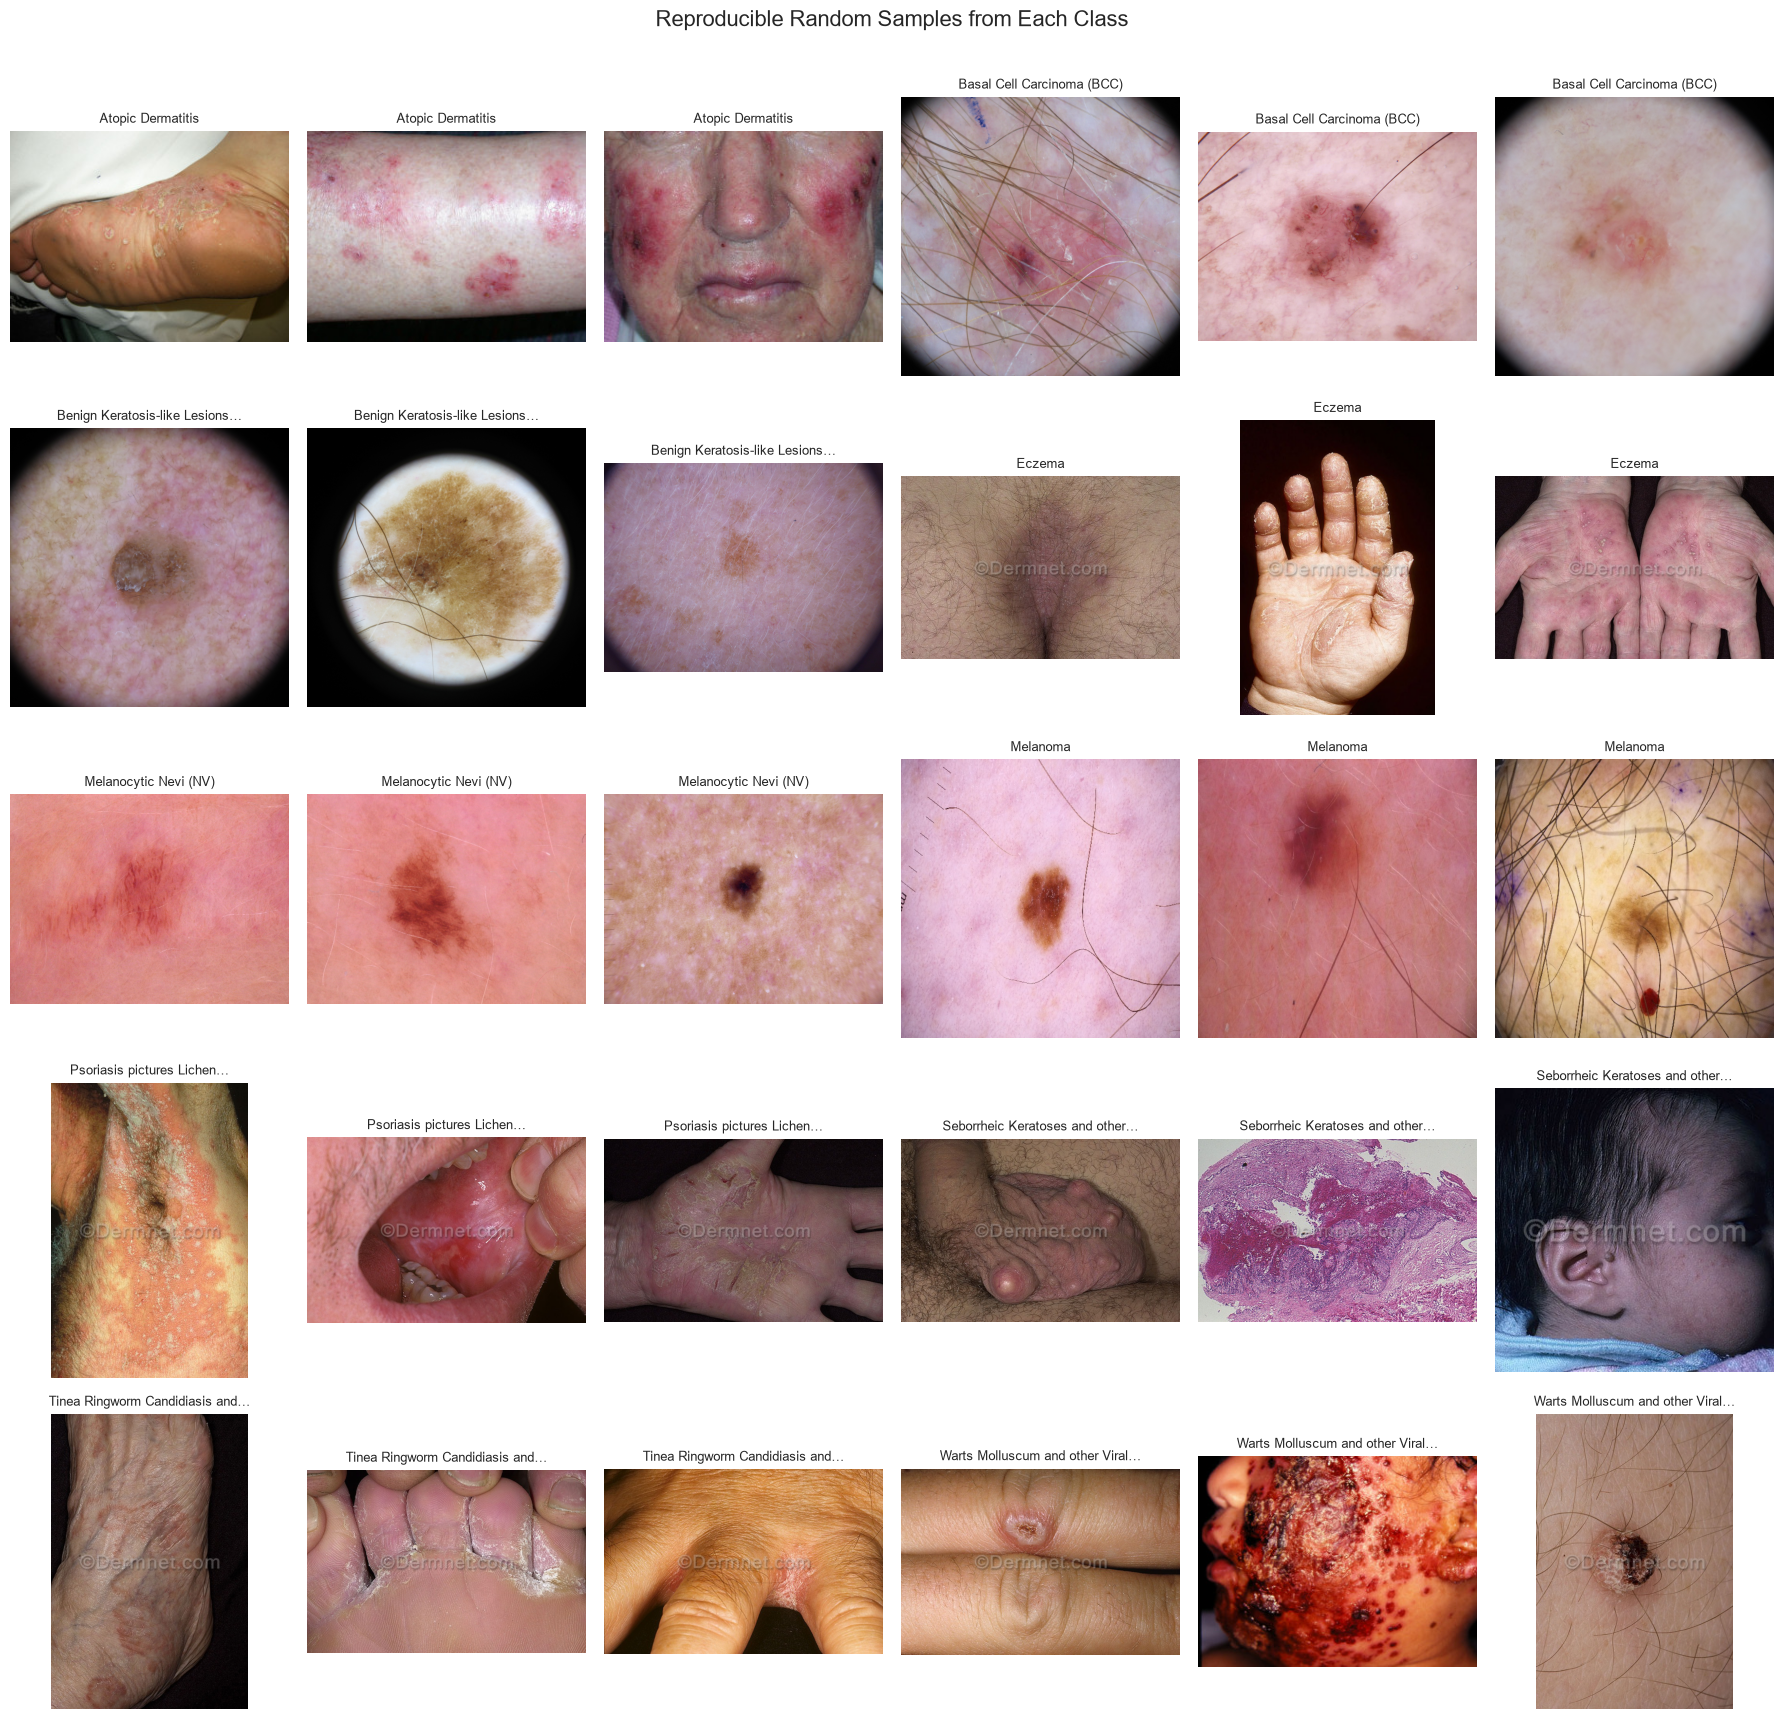

In [8]:
sampled_images = pd.concat(
    [
        group.sample(n=min(3, len(group)), random_state=RANDOM_SEED)
        for _, group in df_images.groupby("class_name", sort=True)
    ],
    ignore_index=True,
)

samples_per_row = 6
n_sample_rows = int(np.ceil(len(sampled_images) / samples_per_row))
fig, axes = plt.subplots(
    n_sample_rows,
    samples_per_row,
    figsize=(18, 3.4 * n_sample_rows),
    squeeze=False,
)

for ax, (_, row) in zip(axes.flat, sampled_images.iterrows()):
    image_path = PROJECT_ROOT / row["file_path"]
    try:
        with Image.open(image_path) as image:
            display_image = np.asarray(ImageOps.exif_transpose(image).convert("RGB"))
        ax.imshow(display_image)
        ax.set_title(textwrap.shorten(row["class_name"], width=32, placeholder="…"), fontsize=9)
    except Exception as error:
        ax.text(
            0.5,
            0.5,
            f"Could not display image\n{type(error).__name__}",
            ha="center",
            va="center",
        )
        ax.set_title(textwrap.shorten(row["class_name"], width=32, placeholder="…"), fontsize=9)
    ax.axis("off")

for ax in axes.flat[len(sampled_images):]:
    ax.axis("off")

fig.suptitle("Reproducible Random Samples from Each Class", fontsize=16, y=1.01)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_random_class_samples.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Exact Duplicate Detection

SHA-256 hashes are computed from complete file bytes. Matching hashes identify byte-for-byte duplicate files. Results distinguish duplicate groups confined to one class from groups crossing class boundaries. No duplicates are removed.

In [9]:
def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    """Return a file's SHA-256 digest without loading the whole file into memory."""
    digest = hashlib.sha256()
    with path.open("rb") as file_handle:
        for chunk in iter(lambda: file_handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


hash_records = []
hash_errors = []
for path in tqdm(all_files, desc="Computing SHA-256 hashes", unit="file"):
    directory_name = path.relative_to(DATA_DIR).parts[0]
    try:
        hash_records.append(
            {
                "hash": sha256_file(path),
                "file_path": path.relative_to(PROJECT_ROOT).as_posix(),
                "class_name": class_name_by_directory[directory_name],
            }
        )
    except Exception as error:
        hash_errors.append(
            {
                "file_path": path.relative_to(PROJECT_ROOT).as_posix(),
                "class_name": class_name_by_directory[directory_name],
                "error_message": f"{type(error).__name__}: {error}",
            }
        )

if hash_errors:
    raise RuntimeError(
        f"SHA-256 hashing failed for {len(hash_errors)} file(s). "
        "Review the hash error records before interpreting duplicate results."
    )

df_hashes = pd.DataFrame(hash_records)
hash_group_summary = (
    df_hashes.groupby("hash")
    .agg(
        duplicate_group_size=("file_path", "size"),
        class_count=("class_name", "nunique"),
    )
    .reset_index()
)
duplicate_hash_groups = hash_group_summary.loc[
    hash_group_summary["duplicate_group_size"] > 1
].copy()
duplicate_hash_groups["duplicate_scope"] = np.where(
    duplicate_hash_groups["class_count"] > 1,
    "across different classes",
    "within the same class",
)

exact_duplicates_df = (
    df_hashes.merge(duplicate_hash_groups, on="hash", how="inner")
    .sort_values(
        ["class_count", "duplicate_group_size", "hash", "class_name", "file_path"],
        ascending=[False, False, True, True, True],
    )
    .reset_index(drop=True)
)
exact_duplicates_df.to_csv(
    REPORTS_DIR / "01_exact_duplicates.csv", index=False, encoding="utf-8"
)

same_class_duplicates = exact_duplicates_df.loc[
    exact_duplicates_df["class_count"] == 1
].copy()
cross_class_duplicates = exact_duplicates_df.loc[
    exact_duplicates_df["class_count"] > 1
].copy()

unique_image_hashes = int(df_hashes["hash"].nunique())
exact_duplicate_group_count = int(duplicate_hash_groups["hash"].nunique())
exact_duplicate_image_count = len(exact_duplicates_df)
largest_exact_duplicate_group = (
    int(duplicate_hash_groups["duplicate_group_size"].max())
    if not duplicate_hash_groups.empty
    else 0
)
exact_redundant_copy_count = int(
    (duplicate_hash_groups["duplicate_group_size"] - 1).sum()
)
cross_class_exact_group_count = int(
    duplicate_hash_groups.loc[duplicate_hash_groups["class_count"] > 1, "hash"].nunique()
)

print(f"Unique SHA-256 hashes: {unique_image_hashes:,}")
print(f"Images involved in exact duplicate groups: {exact_duplicate_image_count:,}")
print(f"Exact duplicate groups: {exact_duplicate_group_count:,}")
print(f"Redundant exact copies beyond one file per group: {exact_redundant_copy_count:,}")
print(f"Largest exact duplicate group: {largest_exact_duplicate_group:,} images")
print(f"Within-class exact duplicate groups: {int((duplicate_hash_groups['class_count'] == 1).sum()):,}")
print(f"Cross-class exact duplicate groups: {cross_class_exact_group_count:,}")

print("A. Exact duplicates within the same class (preview):")
if same_class_duplicates.empty:
    print("No within-class exact duplicates were detected.")
else:
    display(same_class_duplicates.head(20))

print("B. Exact duplicates across different classes (preview):")
if cross_class_duplicates.empty:
    print("No cross-class exact duplicates were detected.")
else:
    display(cross_class_duplicates.head(20))

Computing SHA-256 hashes:   0%|          | 0/27153 [00:00<?, ?file/s]

Unique SHA-256 hashes: 26,529
Images involved in exact duplicate groups: 1,212
Exact duplicate groups: 588
Redundant exact copies beyond one file per group: 624
Largest exact duplicate group: 4 images
Within-class exact duplicate groups: 471
Cross-class exact duplicate groups: 117
A. Exact duplicates within the same class (preview):


,hash,file_path,class_name,duplicate_group_size,class_count,duplicate_scope
240,88d082a411de22e48d2d602fea94266796d95a24c0d396ea8fe5984f7a4f2437,data/raw/skin-diseases-image-dataset/IMG_CLASSES/10. Warts Molluscum and other Viral Infections ...,Warts Molluscum and other Viral Infections,4,1,within the same class
241,88d082a411de22e48d2d602fea94266796d95a24c0d396ea8fe5984f7a4f2437,data/raw/skin-diseases-image-dataset/IMG_CLASSES/10. Warts Molluscum and other Viral Infections ...,Warts Molluscum and other Viral Infections,4,1,within the same class
242,88d082a411de22e48d2d602fea94266796d95a24c0d396ea8fe5984f7a4f2437,data/raw/skin-diseases-image-dataset/IMG_CLASSES/10. Warts Molluscum and other Viral Infections ...,Warts Molluscum and other Viral Infections,4,1,within the same class
243,88d082a411de22e48d2d602fea94266796d95a24c0d396ea8fe5984f7a4f2437,data/raw/skin-diseases-image-dataset/IMG_CLASSES/10. Warts Molluscum and other Viral Infections ...,Warts Molluscum and other Viral Infections,4,1,within the same class
244,93eaf59854e1454038b339584abfa4fc4e968c136daef3c430bf61a92fb6c6c4,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/t-eczema-arms-7.jpg,Eczema,4,1,within the same class
245,93eaf59854e1454038b339584abfa4fc4e968c136daef3c430bf61a92fb6c6c4,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/t-eczema-subacute-13.jpg,Eczema,4,1,within the same class
246,93eaf59854e1454038b339584abfa4fc4e968c136daef3c430bf61a92fb6c6c4,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/t-eczema-subacute-14.jpg,Eczema,4,1,within the same class
247,93eaf59854e1454038b339584abfa4fc4e968c136daef3c430bf61a92fb6c6c4,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/v-eczema-chronic-2.jpg,Eczema,4,1,within the same class
248,b00470a0a448005495959dd80d2ce3fd780dda6f6687767053d6d980ff0be749,data/raw/skin-diseases-image-dataset/IMG_CLASSES/10. Warts Molluscum and other Viral Infections ...,Warts Molluscum and other Viral Infections,4,1,within the same class
249,b00470a0a448005495959dd80d2ce3fd780dda6f6687767053d6d980ff0be749,data/raw/skin-diseases-image-dataset/IMG_CLASSES/10. Warts Molluscum and other Viral Infections ...,Warts Molluscum and other Viral Infections,4,1,within the same class


B. Exact duplicates across different classes (preview):


,hash,file_path,class_name,duplicate_group_size,class_count,duplicate_scope
0,ddccb518414c69c853d89bfc35c474fb8e5f602771caa3862425278ce6566c16,data/raw/skin-diseases-image-dataset/IMG_CLASSES/3. Atopic Dermatitis - 1.25k/6_184.jpg,Atopic Dermatitis,4,2,across different classes
1,ddccb518414c69c853d89bfc35c474fb8e5f602771caa3862425278ce6566c16,data/raw/skin-diseases-image-dataset/IMG_CLASSES/3. Atopic Dermatitis - 1.25k/6_202.jpg,Atopic Dermatitis,4,2,across different classes
2,ddccb518414c69c853d89bfc35c474fb8e5f602771caa3862425278ce6566c16,data/raw/skin-diseases-image-dataset/IMG_CLASSES/10. Warts Molluscum and other Viral Infections ...,Warts Molluscum and other Viral Infections,4,2,across different classes
3,ddccb518414c69c853d89bfc35c474fb8e5f602771caa3862425278ce6566c16,data/raw/skin-diseases-image-dataset/IMG_CLASSES/10. Warts Molluscum and other Viral Infections ...,Warts Molluscum and other Viral Infections,4,2,across different classes
4,8934f60c4afb57686724f07d6dd05b104e1ea1de1cbda46a19e1cc4cca630b52,data/raw/skin-diseases-image-dataset/IMG_CLASSES/3. Atopic Dermatitis - 1.25k/6_255.jpg,Atopic Dermatitis,3,2,across different classes
5,8934f60c4afb57686724f07d6dd05b104e1ea1de1cbda46a19e1cc4cca630b52,data/raw/skin-diseases-image-dataset/IMG_CLASSES/3. Atopic Dermatitis - 1.25k/6_289.jpg,Atopic Dermatitis,3,2,across different classes
6,8934f60c4afb57686724f07d6dd05b104e1ea1de1cbda46a19e1cc4cca630b52,data/raw/skin-diseases-image-dataset/IMG_CLASSES/7. Psoriasis pictures Lichen Planus and related...,Psoriasis pictures Lichen Planus and related diseases,3,2,across different classes
7,aae916c36236f602b80c1120e64c6dd5093048eae705817411da4f9f7fe9fbfe,data/raw/skin-diseases-image-dataset/IMG_CLASSES/3. Atopic Dermatitis - 1.25k/6_103.jpg,Atopic Dermatitis,3,2,across different classes
8,aae916c36236f602b80c1120e64c6dd5093048eae705817411da4f9f7fe9fbfe,data/raw/skin-diseases-image-dataset/IMG_CLASSES/3. Atopic Dermatitis - 1.25k/6_91.jpg,Atopic Dermatitis,3,2,across different classes
9,aae916c36236f602b80c1120e64c6dd5093048eae705817411da4f9f7fe9fbfe,data/raw/skin-diseases-image-dataset/IMG_CLASSES/7. Psoriasis pictures Lichen Planus and related...,Psoriasis pictures Lichen Planus and related diseases,3,2,across different classes


## 10. Perceptual / Near-Duplicate Candidate Check

A 64-bit difference hash (dHash) is calculated after EXIF orientation correction and grayscale resizing. To avoid a naive all-pairs comparison, each hash is divided into three segments. With a Hamming-distance threshold of two, any qualifying pair must match in at least one segment, so only hashes sharing a segment are compared.

Connected groups include identical perceptual hashes and pairs at Hamming distance ≤ 2. These are **near-duplicate candidates**, not confirmed duplicates, and require visual review.

In [10]:
PERCEPTUAL_HASH_SIZE = 8
MAX_HAMMING_DISTANCE = 2


def difference_hash(path: Path, hash_size: int = PERCEPTUAL_HASH_SIZE) -> str:
    """Compute a 64-bit dHash as a fixed-width hexadecimal string."""
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert("L")
        image = image.resize((hash_size + 1, hash_size), Image.Resampling.LANCZOS)
        pixels = np.asarray(image, dtype=np.int16)
    differences = pixels[:, 1:] > pixels[:, :-1]
    hash_value = 0
    for bit in differences.ravel():
        hash_value = (hash_value << 1) | int(bit)
    return f"{hash_value:0{hash_size * hash_size // 4}x}"


perceptual_records = []
perceptual_errors = []
for row in tqdm(
    df_images.itertuples(index=False),
    total=len(df_images),
    desc="Computing dHashes",
    unit="image",
):
    path = PROJECT_ROOT / row.file_path
    try:
        perceptual_records.append(
            {
                "perceptual_hash": difference_hash(path),
                "file_path": row.file_path,
                "class_name": row.class_name,
            }
        )
    except Exception as error:
        perceptual_errors.append(
            {
                "file_path": row.file_path,
                "class_name": row.class_name,
                "error_message": f"{type(error).__name__}: {error}",
            }
        )

if perceptual_errors:
    print(f"Perceptual hashing failed for {len(perceptual_errors):,} valid image(s):")
    display(pd.DataFrame(perceptual_errors))

df_perceptual = pd.DataFrame(perceptual_records)


def close_hash_pairs(hash_strings, max_distance: int = 2):
    """Find close 64-bit hashes using segment buckets instead of all-pairs search."""
    hash_values = sorted({int(value, 16) for value in hash_strings})
    segment_bounds = [(0, 22), (22, 43), (43, 64)]
    buckets = defaultdict(list)

    for hash_value in hash_values:
        for segment_index, (start, stop) in enumerate(segment_bounds):
            mask = (1 << (stop - start)) - 1
            buckets[(segment_index, (hash_value >> start) & mask)].append(hash_value)

    close_pairs = set()
    for bucket_values in buckets.values():
        if len(bucket_values) < 2:
            continue
        for left, right in combinations(bucket_values, 2):
            if (left ^ right).bit_count() <= max_distance:
                close_pairs.add((min(left, right), max(left, right)))
    return hash_values, close_pairs


unique_hash_values, perceptually_close_pairs = close_hash_pairs(
    df_perceptual["perceptual_hash"], MAX_HAMMING_DISTANCE
)
parent = {hash_value: hash_value for hash_value in unique_hash_values}


def find_root(value):
    while parent[value] != value:
        parent[value] = parent[parent[value]]
        value = parent[value]
    return value


def union(left, right):
    left_root, right_root = find_root(left), find_root(right)
    if left_root != right_root:
        parent[max(left_root, right_root)] = min(left_root, right_root)


for left_hash, right_hash in perceptually_close_pairs:
    union(left_hash, right_hash)

hash_image_counts = Counter(
    int(value, 16) for value in df_perceptual["perceptual_hash"]
)
component_hashes = defaultdict(list)
for hash_value in unique_hash_values:
    component_hashes[find_root(hash_value)].append(hash_value)

candidate_components = [
    values
    for values in component_hashes.values()
    if sum(hash_image_counts[value] for value in values) > 1
]
candidate_components.sort(
    key=lambda values: (-sum(hash_image_counts[value] for value in values), min(values))
)

candidate_group_by_hash = {}
for group_number, component in enumerate(candidate_components, start=1):
    group_id = f"DHASH_{group_number:05d}"
    for hash_value in component:
        candidate_group_by_hash[f"{hash_value:016x}"] = group_id

near_duplicates_df = df_perceptual.loc[
    df_perceptual["perceptual_hash"].isin(candidate_group_by_hash)
].copy()
near_duplicates_df["candidate_group"] = near_duplicates_df["perceptual_hash"].map(
    candidate_group_by_hash
)

if not near_duplicates_df.empty:
    near_duplicates_df["candidate_group_size"] = near_duplicates_df.groupby(
        "candidate_group"
    )["file_path"].transform("size")
    near_duplicates_df["class_count"] = near_duplicates_df.groupby(
        "candidate_group"
    )["class_name"].transform("nunique")
    near_duplicates_df["cross_class_candidate"] = near_duplicates_df["class_count"] > 1
    near_duplicates_df["method"] = (
        f"64-bit dHash connected component, Hamming distance <= {MAX_HAMMING_DISTANCE}"
    )
    near_duplicates_df = near_duplicates_df.sort_values(
        ["cross_class_candidate", "candidate_group_size", "candidate_group", "class_name", "file_path"],
        ascending=[False, False, True, True, True],
    ).reset_index(drop=True)
else:
    near_duplicates_df = pd.DataFrame(
        columns=[
            "perceptual_hash",
            "file_path",
            "class_name",
            "candidate_group",
            "candidate_group_size",
            "class_count",
            "cross_class_candidate",
            "method",
        ]
    )

near_duplicates_df.to_csv(
    REPORTS_DIR / "01_near_duplicate_candidates.csv", index=False, encoding="utf-8"
)

near_duplicate_group_count = int(near_duplicates_df["candidate_group"].nunique())
near_duplicate_image_count = len(near_duplicates_df)
cross_class_near_group_count = int(
    near_duplicates_df.loc[
        near_duplicates_df["cross_class_candidate"] == True, "candidate_group"
    ].nunique()
)
identical_dhash_group_count = int(
    (df_perceptual.groupby("perceptual_hash").size() > 1).sum()
)

print(f"Identical perceptual-hash groups: {identical_dhash_group_count:,}")
print(f"Near-duplicate candidate groups: {near_duplicate_group_count:,}")
print(f"Images involved in candidate groups: {near_duplicate_image_count:,}")
print(f"Cross-class candidate groups: {cross_class_near_group_count:,}")
if near_duplicates_df.empty:
    print("No near-duplicate candidates were detected with the selected dHash criterion.")
else:
    print("Near-duplicate candidate preview (full results are saved to CSV):")
    display(near_duplicates_df.head(30))

Computing dHashes:   0%|          | 0/27153 [00:00<?, ?image/s]

Identical perceptual-hash groups: 739
Near-duplicate candidate groups: 887
Images involved in candidate groups: 3,576
Cross-class candidate groups: 207
Near-duplicate candidate preview (full results are saved to CSV):


,perceptual_hash,file_path,class_name,candidate_group,candidate_group_size,class_count,cross_class_candidate,method
0,f0f0f0f0f0d0f0f0,data/raw/skin-diseases-image-dataset/IMG_CLASSES/3. Atopic Dermatitis - 1.25k/1_41.jpg,Atopic Dermatitis,DHASH_00001,1327,10,True,"64-bit dHash connected component, Hamming distance <= 2"
1,f0f0f8f8f8f8f0e8,data/raw/skin-diseases-image-dataset/IMG_CLASSES/3. Atopic Dermatitis - 1.25k/1_45.jpg,Atopic Dermatitis,DHASH_00001,1327,10,True,"64-bit dHash connected component, Hamming distance <= 2"
2,f0f0e0e0e0e0e0e0,data/raw/skin-diseases-image-dataset/IMG_CLASSES/3. Atopic Dermatitis - 1.25k/1_46.jpg,Atopic Dermatitis,DHASH_00001,1327,10,True,"64-bit dHash connected component, Hamming distance <= 2"
3,f0f0e8f8f0f0f0f0,data/raw/skin-diseases-image-dataset/IMG_CLASSES/3. Atopic Dermatitis - 1.25k/1_8.jpg,Atopic Dermatitis,DHASH_00001,1327,10,True,"64-bit dHash connected component, Hamming distance <= 2"
4,f8f0f0f0f0f0f0f0,data/raw/skin-diseases-image-dataset/IMG_CLASSES/3. Atopic Dermatitis - 1.25k/5_0.jpg,Atopic Dermatitis,DHASH_00001,1327,10,True,"64-bit dHash connected component, Hamming distance <= 2"
5,70f0f0f0f0f0f0e8,data/raw/skin-diseases-image-dataset/IMG_CLASSES/3. Atopic Dermatitis - 1.25k/5_1.jpg,Atopic Dermatitis,DHASH_00001,1327,10,True,"64-bit dHash connected component, Hamming distance <= 2"
6,f0f0f0f0f0707071,data/raw/skin-diseases-image-dataset/IMG_CLASSES/3. Atopic Dermatitis - 1.25k/6_135.jpg,Atopic Dermatitis,DHASH_00001,1327,10,True,"64-bit dHash connected component, Hamming distance <= 2"
7,f0f0f0f0e0e0f0e0,data/raw/skin-diseases-image-dataset/IMG_CLASSES/3. Atopic Dermatitis - 1.25k/6_177.jpg,Atopic Dermatitis,DHASH_00001,1327,10,True,"64-bit dHash connected component, Hamming distance <= 2"
8,b0f0f0f0f0f0f0f0,data/raw/skin-diseases-image-dataset/IMG_CLASSES/3. Atopic Dermatitis - 1.25k/6_214.jpg,Atopic Dermatitis,DHASH_00001,1327,10,True,"64-bit dHash connected component, Hamming distance <= 2"
9,f0f0f0f0f0f0f0f0,data/raw/skin-diseases-image-dataset/IMG_CLASSES/3. Atopic Dermatitis - 1.25k/6_299.jpg,Atopic Dermatitis,DHASH_00001,1327,10,True,"64-bit dHash connected component, Hamming distance <= 2"


## Dataset Audit Summary

The following summary is generated from verified results rather than manually entered observations.

In [11]:
format_description = (
    "all discovered files use JPG/JPEG extensions"
    if format_is_consistent
    else "more than one file-extension family is present"
)
corruption_description = (
    "no corrupted or unreadable images were detected"
    if df_corrupted.empty
    else f"{len(df_corrupted):,} corrupted or unreadable image(s) were detected"
)
exact_cross_class_description = (
    "no cross-class exact duplicate groups were detected"
    if cross_class_exact_group_count == 0
    else f"{cross_class_exact_group_count:,} cross-class exact duplicate group(s) were detected"
)
near_cross_class_description = (
    "no cross-class near-duplicate candidate groups were detected"
    if cross_class_near_group_count == 0
    else f"{cross_class_near_group_count:,} cross-class near-duplicate candidate group(s) were detected"
)

summary_markdown = f"""
- **Dataset size:** {total_images:,} files across {len(class_dirs):,} classes.
- **Class distribution:** the largest class has {imbalance_ratio:.2f} times as many images as the smallest class, confirming unequal class sizes.
- **Image integrity:** {corruption_description} among {len(df_integrity):,} checked files.
- **Format consistency:** {format_description}.
- **Resolution variability:** {len(resolution_counts):,} unique width–height combinations were observed; widths range from {int(df_images['width'].min()):,} to {int(df_images['width'].max()):,} pixels and heights from {int(df_images['height'].min()):,} to {int(df_images['height'].max()):,} pixels.
- **Exact duplicates:** {exact_duplicate_group_count:,} group(s) involve {exact_duplicate_image_count:,} images ({exact_redundant_copy_count:,} redundant copies); {exact_cross_class_description}.
- **Near-duplicate candidates:** {near_duplicate_group_count:,} dHash candidate group(s) involve {near_duplicate_image_count:,} images; {near_cross_class_description}. These candidates require visual confirmation.
"""
display(Markdown(summary_markdown))


- **Dataset size:** 27,153 files across 10 classes.
- **Class distribution:** the largest class has 6.34 times as many images as the smallest class, confirming unequal class sizes.
- **Image integrity:** no corrupted or unreadable images were detected among 27,153 checked files.
- **Format consistency:** all discovered files use JPG/JPEG extensions.
- **Resolution variability:** 390 unique width–height combinations were observed; widths range from 294 to 1,024 pixels and heights from 222 to 1,128 pixels.
- **Exact duplicates:** 588 group(s) involve 1,212 images (624 redundant copies); 117 cross-class exact duplicate group(s) were detected.
- **Near-duplicate candidates:** 887 dHash candidate group(s) involve 3,576 images; 207 cross-class near-duplicate candidate group(s) were detected. These candidates require visual confirmation.


### Implications for the Next Stage

The next stage should use stratified splitting so that the observed class distribution is represented consistently. Any exact duplicates and visually confirmed near-duplicates should be assigned as groups to a single data partition to prevent leakage, with cross-class cases reviewed before modeling. A common input resolution should be selected using the measured resolution distribution, while preserving aspect ratio through a documented resizing or padding policy. Class weighting, sampling, or augmentation should be considered only after measuring the impact of the observed imbalance, and augmentation must be applied only to training data. An untouched final test set should be preserved for unbiased evaluation.

This notebook intentionally does not create dataset splits, transform or augment images, or train a model.

## Generated Audit Artifacts

Reusable tables are saved as:

- `reports/01_class_distribution.csv`
- `reports/01_image_metadata.csv`
- `reports/01_exact_duplicates.csv`
- `reports/01_near_duplicate_candidates.csv`

Figures are saved under `reports/figures/` with the `01_` prefix. No files are written to or modified within `data/raw/`.